# Supporting Datasets: EDA and Data Cleaning with Spark (Requirement 3)

Goal: explore and check the quality of every supporting dataset before modeling: CTA 'L' and bus ridership, 'L' stop locations, community area boundaries, socioeconomic indicators, ACS population, and NOAA weather. The trip data is covered in `01_data_quality_full.ipynb` and `03_trip_eda.ipynb`.

How it ran: all statistics, outlier checks and cleaning diagnostics are computed by the Spark job `src/eda/supporting_eda.py`, executed on **Google Cloud Dataproc Serverless** (batch `shuss26-supporting-eda-1120`). The job reads every file as text, so it can count values that do not parse, and writes small summary tables plus the cleaned data as Parquet. This notebook only reads those summary tables and plots them.

To reproduce:
```bash
B=gs://ride-or-rail-data-ride-or-rail-123456
gcloud storage cp data/raw/supporting/* $B/inputs/supporting/
gcloud dataproc batches submit pyspark src/eda/supporting_eda.py --region=us-central1 --version=2.2 \
  --deps-bucket=$B -- $B/inputs/supporting $B/results/eda_supporting
for t in diagnostics stats outliers categories histograms; do
  gcloud storage cat "$B/results/eda_supporting/$t/part-*.csv" > results/eda_supporting/$t.csv
done
```

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RES = ROOT / "results" / "eda_supporting"
FIGS = ROOT / "docs" / "figures" / "eda"
FIGS.mkdir(parents=True, exist_ok=True)

diag, stats, outl, cats, hist = (pd.read_csv(RES / f"{t}.csv")
                                 for t in ["diagnostics", "stats", "outliers", "categories", "histograms"])
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e3", "axes.axisbelow": True})
BLUE, ORANGE = "#2a78d6", "#eb6834"

def checks(source):
    """Every check except 'missing' rows that are zero."""
    d = diag[diag.source == source]
    return d[(d.check != "missing") | (d["count"] > 0)].drop(columns="source").fillna("")

def describe(*sources):
    return stats[stats.source.isin(sources)].set_index(["source", "feature"])

def outliers(*sources):
    return outl[outl.source.isin(sources)].set_index(["source", "feature", "method"])

def histogram(ax, source, feature, color=BLUE, label=None):
    h = hist[(hist.source == source) & (hist.feature == feature)].sort_values("bin_lo")
    ax.bar(h.bin_lo, h["count"], width=h.bin_hi - h.bin_lo, align="edge", color=color,
           edgecolor="white", linewidth=0.5, alpha=0.85, label=label)

def boxes(ax, rows, labels):
    """Box plots drawn from the Spark quartiles; whiskers stop at the 1.5 x IQR fences."""
    data = []
    for (_, r), label in zip(rows.iterrows(), labels):
        iqr = r["q3"] - r["q1"]
        data.append({"label": label, "q1": r["q1"], "med": r["median"], "q3": r["q3"], "mean": r["mean"],
                     "whislo": max(r["min"], r["q1"] - 1.5 * iqr), "whishi": min(r["max"], r["q3"] + 1.5 * iqr),
                     "fliers": []})
    ax.bxp(data, showmeans=True, patch_artist=True,
           boxprops={"facecolor": "#cde2fb", "edgecolor": BLUE}, medianprops={"color": BLUE, "linewidth": 2},
           meanprops={"marker": "D", "markerfacecolor": ORANGE, "markeredgecolor": ORANGE, "markersize": 5})

print(diag.source.nunique(), "sources,", len(stats), "features with statistics")

7 sources, 31 features with statistics


## 1. CTA 'L' and bus daily ridership

In [2]:
pd.concat({"'L'": checks("cta_L_daily"), "Bus": checks("cta_bus_daily")})

check           column    count    pct  \
'L' 0                                 rows                   1333391 100.00   
    6                       duplicate rows                         0   0.00   
    7                        duplicate key  station_id+date      618   0.05   
    8                  date does not parse             date        0   0.00   
    9   rides written with thousands comma            rides   962030  72.15   
    10                   rides not numeric            rides        0   0.00   
    11                      negative rides            rides        0   0.00   
    12                   daytype not W/A/U          daytype        0   0.00   
    13  station id with more than one name      stationname        1   0.68   
    14           zero-ride rows since 2018            rides     3851   0.86   
Bus 15                                rows                   1120604 100.00   
    20                      duplicate rows                         0   0.00   
    21                       duplicate key       route+date        0   0.00   
    22                 date does not parse             date        0   0.00   
    23  rides written with thousands comma            rides   888749  79.31   
    24                   rides not numeric            rides        0   0.00   
    25                      negative rides            rides        0   0.00   
    26                   daytype not W/A/U          daytype        0   0.00   
    27          distinct routes since 2018            route      136   0.00   
    28           zero-ride rows since 2018            rides        5   0.00   

                                                note  
'L' 0                                                 
    6                                                 
    7                                                 
    8                            expected MM/DD/YYYY  
    9     formatting only; parsed by removing commas  
    10                                                
    11                                                
    12       W weekday, A Saturday, U Sunday/holiday  
    13  station renamed over time; the id is the key  
    14           closed stations or suspended routes  
Bus 15                                                
    20                                                
    21                                                
    22                           expected MM/DD/YYYY  
    23    formatting only; parsed by removing commas  
    24                                                
    25                                                
    26       W weekday, A Saturday, U Sunday/holiday  
    27                                                
    28           closed stations or suspended routes

In [3]:
describe("cta_L_daily", "cta_bus_daily")

count       mean        std       min  \
source        feature                                                     
cta_L_daily   rides              449320   2,169.41   2,470.56      0.00   
              daily_total_rides    3134 311,026.76 158,736.67 19,120.00   
cta_bus_daily rides              359320   4,200.36   4,226.70      0.00   
              daily_total_rides    3134 481,580.28 189,731.36 80,199.00   

                                        q1     median         q3        max  \
source        feature                                                         
cta_L_daily   rides                 625.00   1,320.00   2,786.00  29,581.00   
              daily_total_rides 196,294.00 290,012.00 375,832.00 708,838.00   
cta_bus_daily rides                 941.00   2,763.00   6,262.00  27,676.00   
              daily_total_rides 321,307.00 465,000.00 629,066.00 907,885.00   

                                 skewness  
source        feature                      
cta_L_daily   rides                  2.90  
              daily_total_rides      0.63  
cta_bus_daily rides                  1.49  
              daily_total_rides      0.23

In [4]:
outliers("cta_L_daily", "cta_bus_daily")

lower        upper  n_low  \
source        feature           method                                   
cta_L_daily   rides             iqr      -2,616.50     6,027.50      0   
                                zscore   -5,242.26     9,581.07      0   
              daily_total_rides iqr     -73,013.00   645,139.00      0   
                                zscore -165,183.24   787,236.76      0   
cta_bus_daily rides             iqr      -7,040.50    14,243.50      0   
                                zscore   -8,479.74    16,880.45      0   
              daily_total_rides iqr    -140,331.50 1,090,704.50      0   
                                zscore  -87,613.80 1,050,774.36      0   

                                        n_high  pct  
source        feature           method               
cta_L_daily   rides             iqr      32130 7.15  
                                zscore    9600 2.14  
              daily_total_rides iqr         55 1.75  
                                zscore       0 0.00  
cta_bus_daily rides             iqr      12521 3.48  
                                zscore    5859 1.63  
              daily_total_rides iqr          0 0.00  
                                zscore       0 0.00

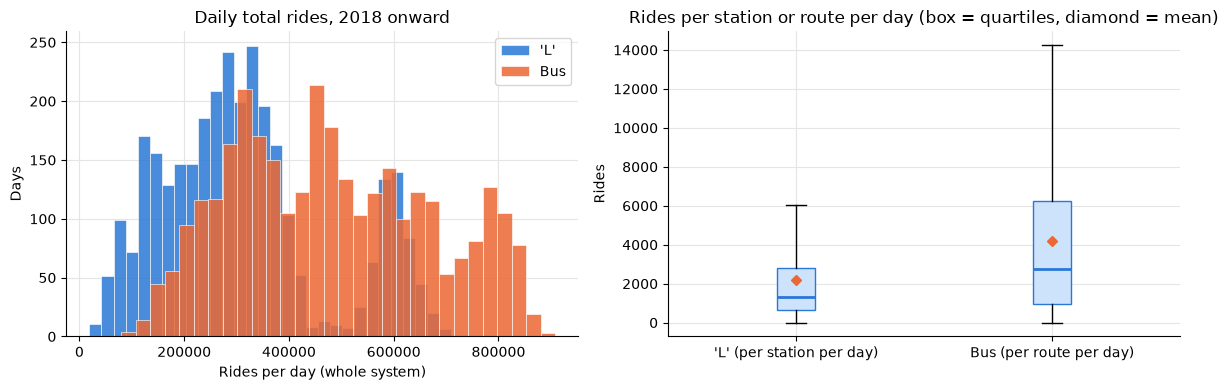

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
histogram(axes[0], "cta_L_daily", "daily_total_rides", BLUE, "'L'")
histogram(axes[0], "cta_bus_daily", "daily_total_rides", ORANGE, "Bus")
axes[0].set(title="Daily total rides, 2018 onward", xlabel="Rides per day (whole system)", ylabel="Days")
axes[0].legend()
boxes(axes[1], describe("cta_L_daily", "cta_bus_daily").loc[[("cta_L_daily", "rides"), ("cta_bus_daily", "rides")]],
      ["'L' (per station per day)", "Bus (per route per day)"])
axes[1].set(title="Rides per station or route per day (box = quartiles, diamond = mean)", ylabel="Rides")
axes[0].ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.savefig(FIGS / "cta_ridership.png", dpi=150, bbox_inches="tight")
plt.show()

**Data quality.** Both files load cleanly in Spark: no dates or ride counts fail to parse, there are no negative values, and every day type is W, A or U. The one formatting problem is that ride counts are written with thousands commas (72% of 'L' rows and 79% of bus rows), so the job removes the commas before casting. The 'L' file has 618 station-days listed twice with slightly different counts; all of them are from summer 2011, outside our 2018+ window, so we keep one copy. One station (40140) changed its name from Skokie to Dempster-Skokie, so we join on the station id, not the name. Since 2018 there are 3,851 'L' station-days with 0 rides, from stations closed for rebuilding (Lawrence, Berwyn, State/Lake, Randolph/Wabash), and only 5 zero rows for buses.

**Distributions.** Since 2018 the 'L' carries a median of 290,012 rides a day and the bus system 465,000. Both histograms have two humps: the higher one is 2018–2019 and the lower one is after COVID. Rides per station or route are right-skewed (skewness 2.9 for 'L' stations): half of the 'L' station-days have fewer than 1,320 rides, but Lake/State averages about 10,000.

**Outliers.** The IQR rule flags 7.2% of 'L' station-days and 3.5% of bus route-days as high, and the z-score rule (|z| > 3) flags 2.1% and 1.6%. These are the busiest downtown stations and routes, not errors, so we keep them and use log scales or per-station comparisons instead. For daily totals, the IQR rule flags 55 'L' days, all in 2018–2019 before COVID; we keep them and, like the rest of the project, model 2023 onward.

## 2. CTA 'L' stops

In [6]:
checks("cta_L_stops")

,check,column,count,pct,note
29,rows,,302,100.00,
46,duplicate rows,,0,0.00,
47,duplicate key,STOP_ID,0,0.00,
48,location does not parse,Location,0,0.00,"expected ""(lat, lon)"""
49,location outside Chicago region,Location,0,0.00,
50,flag not true/false,RED,0,0.00,
51,flag not true/false,BLUE,0,0.00,
52,flag not true/false,G,0,0.00,
53,flag not true/false,BRN,0,0.00,
54,flag not true/false,P,0,0.00,


In [7]:
describe("cta_L_stops")

count   mean  std    min     q1  median     q3    max  \
source      feature                                                          
cta_L_stops lat        302  41.90 0.07  41.72  41.87   41.89  41.95  42.07   
            lon        302 -87.68 0.05 -87.90 -87.71  -87.67 -87.63 -87.61   

                     skewness  
source      feature            
cta_L_stops lat          0.16  
            lon         -1.36

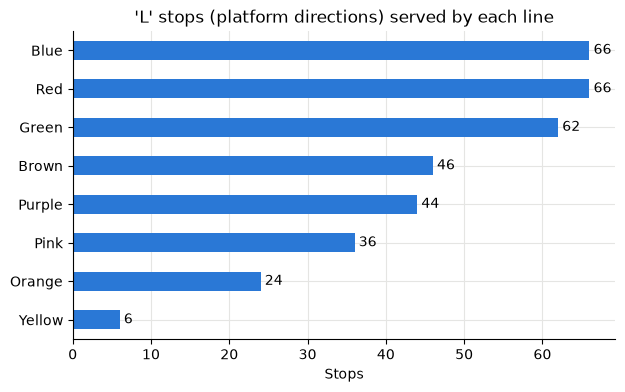

ADA accessible stops: {'true': 224, 'false': 78}


In [8]:
lines = {"RED": "Red", "BLUE": "Blue", "G": "Green", "BRN": "Brown", "P": "Purple", "Y": "Yellow", "Pnk": "Pink", "O": "Orange"}
per_line = (cats[(cats.source == "cta_L_stops") & cats.column.isin(lines) & (cats.value.str.lower() == "true")]
            .assign(line=lambda d: d.column.map(lines)).set_index("line")["count"].sort_values())
ada = cats[(cats.source == "cta_L_stops") & (cats.column == "ADA")].set_index("value")["count"]
ax = per_line.plot(kind="barh", color=BLUE, figsize=(7, 4),
                   title="'L' stops (platform directions) served by each line")
ax.set(xlabel="Stops", ylabel="")
ax.bar_label(ax.containers[0], padding=3)
plt.savefig(FIGS / "l_stops_per_line.png", dpi=150, bbox_inches="tight")
plt.show()
print("ADA accessible stops:", ada.to_dict())

The stops file has 302 rows (one per platform direction) for 144 stations. Every location parses as "(lat, lon)" and falls inside the Chicago region, every line flag is true or false, and there are no duplicate stop ids. The Red and Blue lines have the most stops (66 each) and the Yellow line the fewest (6); 224 of 302 stops (74%) are ADA accessible. The IQR rule flags 4 stops on latitude and 6 on longitude: these are real stations at the far south and far west ends of the lines (for example 95th/Dan Ryan and O'Hare), so we keep them. Cleaning: the location string is parsed into numeric latitude and longitude, and the line flags become true/false columns.

## 3. Community area boundaries

In [9]:
checks("community_areas")

,check,column,count,pct,note
60,rows,,77,100.00,
68,duplicate rows,,0,0.00,
69,duplicate key,area_numbe,0,0.00,
70,area number not 1-77,area_numbe,0,0.00,
71,area_numbe differs from area_num_1,area_num_1,0,0.00,two copies of the same id
72,missing geometry,geometry,0,0.00,


In [10]:
describe("community_areas")

count  mean  std  min   q1  median    q3   max  \
source          feature                                                        
community_areas area_km2         77  7.77 5.10 1.57 4.62    7.40  9.18 34.54   
                perimeter_km     77 13.53 6.12 5.53 9.74   13.18 15.08 52.92   

                              skewness  
source          feature                 
community_areas area_km2          2.78  
                perimeter_km      3.63

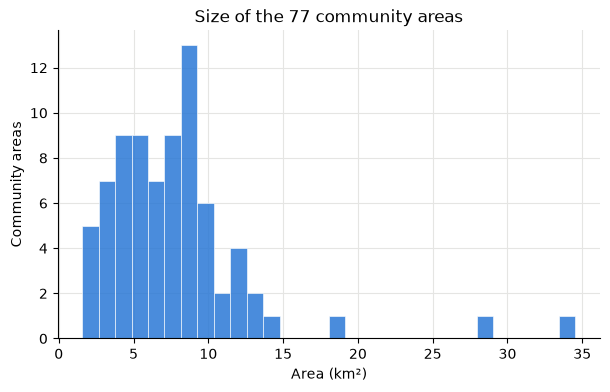

lower  upper  n_low  n_high  pct
source          feature      method                                  
community_areas area_km2     iqr     -2.22  16.02      0       3 3.90
                             zscore  -7.55  23.08      0       2 2.60
                perimeter_km iqr      1.72  23.10      0       3 3.90
                             zscore  -4.84  31.90      0       1 1.30

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
histogram(ax, "community_areas", "area_km2")
ax.set(title="Size of the 77 community areas", xlabel="Area (km²)", ylabel="Community areas")
plt.savefig(FIGS / "community_area_size.png", dpi=150, bbox_inches="tight")
plt.show()
outliers("community_areas")

All 77 community areas are present, numbered 1 to 77 with no gaps or duplicates, every area has a geometry, and the file's two copies of the area number always agree. The median area is 7.4 km², but sizes are right-skewed: the IQR rule flags O'Hare (34.5 km²), South Deering (28.2 km²) and Austin (18.5 km²) as large. These are real boundaries, so we keep them; it is one reason we compare areas by trips per person or per km² instead of total trips. Cleaning: `shape_area` is in square feet, so it is converted to km².

## 4. Socioeconomic indicators by community area (2008–2012)

In [12]:
checks("socioeconomic")

,check,column,count,pct,note
73,rows,,78,100.00,
74,missing,community_area_number,1,1.28,
82,missing,hardship_index,1,1.28,
83,duplicate rows,,0,0.00,
84,duplicate key,community_area_number,0,0.00,
85,row without area number (city total),community_area_number,1,1.28,CHICAGO row; removed
86,indicator not numeric,all,1,1.28,
87,percentage outside 0-100,percent_*,0,0.00,
88,hardship index outside 1-100,hardship_index,0,0.00,


In [13]:
describe("socioeconomic")

count      mean  \
source        feature                                                        
socioeconomic percent_of_housing_crowded                      77      4.92   
              percent_households_below_poverty                77     21.77   
              percent_aged_16_unemployed                      77     15.37   
              percent_aged_25_without_high_school_diploma     77     20.34   
              percent_aged_under_18_or_over_64                77     35.75   
              per_capita_income                               77 25,563.17   
              hardship_index                                  77     49.51   

                                                                std      min  \
source        feature                                                          
socioeconomic percent_of_housing_crowded                       3.68     0.30   
              percent_households_below_poverty                11.53     3.30   
              percent_aged_16_unemployed                       7.54     4.70   
              percent_aged_25_without_high_school_diploma     11.82     2.50   
              percent_aged_under_18_or_over_64                 7.33    13.50   
              per_capita_income                           15,293.10 8,201.00   
              hardship_index                                  28.69     1.00   

                                                                 q1    median  \
source        feature                                                           
socioeconomic percent_of_housing_crowded                       2.30      3.80   
              percent_households_below_poverty                13.20     18.90   
              percent_aged_16_unemployed                       9.20     13.90   
              percent_aged_25_without_high_school_diploma     11.80     18.50   
              percent_aged_under_18_or_over_64                32.00     38.10   
              per_capita_income                           15,754.00 21,323.00   
              hardship_index                                  25.00     50.00   

                                                                 q3       max  \
source        feature                                                           
socioeconomic percent_of_housing_crowded                       6.80     15.80   
              percent_households_below_poverty                29.20     56.50   
              percent_aged_16_unemployed                      20.00     35.90   
              percent_aged_25_without_high_school_diploma     26.60     54.80   
              percent_aged_under_18_or_over_64                40.50     51.50   
              per_capita_income                           28,887.00 88,669.00   
              hardship_index                                  74.00     98.00   

                                                           skewness  
source        feature                                                
socioeconomic percent_of_housing_crowded                       1.21  
              percent_households_below_poverty                 0.80  
              percent_aged_16_unemployed                       0.72  
              percent_aged_25_without_high_school_diploma      0.70  
              percent_aged_under_18_or_over_64                -0.98  
              per_capita_income                                1.86  
              hardship_index                                  -0.00

In [14]:
outliers("socioeconomic")

lower  \
source        feature                                     method              
socioeconomic percent_of_housing_crowded                  iqr         -4.45   
                                                          zscore      -6.13   
              percent_households_below_poverty            iqr        -10.80   
                                                          zscore     -12.82   
              percent_aged_16_unemployed                  iqr         -7.00   
                                                          zscore      -7.26   
              percent_aged_25_without_high_school_diploma iqr        -10.40   
                                                          zscore     -15.13   
              percent_aged_under_18_or_over_64            iqr         19.25   
                                                          zscore      13.76   
              per_capita_income                           iqr     -3,945.50   
                                                          zscore -20,316.13   
              hardship_index                              iqr        -48.50   
                                                          zscore     -36.57   

                                                                     upper  \
source        feature                                     method             
socioeconomic percent_of_housing_crowded                  iqr        13.55   
                                                          zscore     15.97   
              percent_households_below_poverty            iqr        53.20   
                                                          zscore     56.36   
              percent_aged_16_unemployed                  iqr        36.20   
                                                          zscore     38.00   
              percent_aged_25_without_high_school_diploma iqr        48.80   
                                                          zscore     55.81   
              percent_aged_under_18_or_over_64            iqr        53.25   
                                                          zscore     57.73   
              per_capita_income                           iqr    48,586.50   
                                                          zscore 71,442.46   
              hardship_index                              iqr       147.50   
                                                          zscore    135.58   

                                                                  n_low  \
source        feature                                     method          
socioeconomic percent_of_housing_crowded                  iqr         0   
                                                          zscore      0   
              percent_households_below_poverty            iqr         0   
                                                          zscore      0   
              percent_aged_16_unemployed                  iqr         0   
                                                          zscore      0   
              percent_aged_25_without_high_school_diploma iqr         0   
                                                          zscore      0   
              percent_aged_under_18_or_over_64            iqr         2   
                                                          zscore      1   
              per_capita_income                           iqr         0   
                                                          zscore      0   
              hardship_index                              iqr         0   
                                                          zscore      0   

                                                                  n_high  pct  
source        feature                                     method               
socioeconomic percent_of_housing_crowded                  iqr          4 5.19  
                                                          zscore       0 0.00  
              percent_households_be

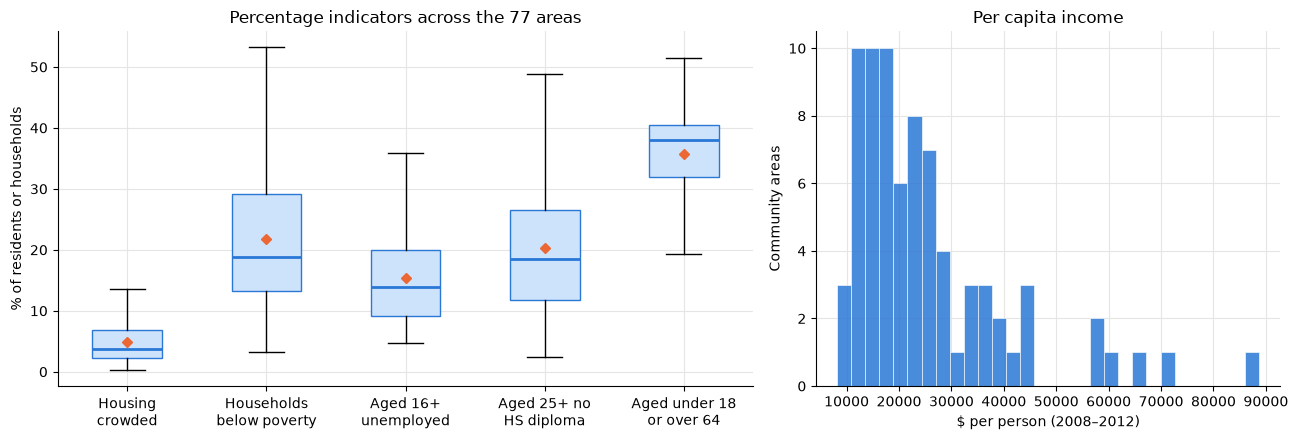

In [15]:
pct = describe("socioeconomic").loc["socioeconomic"].filter(like="percent", axis=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [3, 2]})
boxes(axes[0], pct, ["Housing\ncrowded", "Households\nbelow poverty", "Aged 16+\nunemployed",
                     "Aged 25+ no\nHS diploma", "Aged under 18\nor over 64"])
axes[0].set(title="Percentage indicators across the 77 areas", ylabel="% of residents or households")
histogram(axes[1], "socioeconomic", "per_capita_income")
axes[1].set(title="Per capita income", xlabel="$ per person (2008–2012)", ylabel="Community areas")
plt.tight_layout()
plt.savefig(FIGS / "socioeconomic.png", dpi=150, bbox_inches="tight")
plt.show()

The file has 78 rows: the 77 community areas plus one city-wide row (CHICAGO) with no area number, which we remove. After that there are no missing values or duplicates, all percentages are between 0 and 100, and the hardship index goes from 1 to 98. Per capita income is the most skewed feature (skewness 1.9): the median area has \$21,323, but the IQR rule flags 6 high-income areas, led by the Near North Side (\$88,669) and Lincoln Park (\$71,551). Poverty goes from 3.3% to 56.5% of households, and Riverdale is the only IQR outlier. These are real differences between neighborhoods, so we keep every area and use log income or ranks when we combine income with other features. The data is from 2008–2012, so it is older than the trips.

## 5. ACS 5-year data by community area

In [16]:
checks("acs")

,check,column,count,pct,note
89,rows,,77,100.00,
120,duplicate rows,,0,0.00,
121,duplicate key,Community Area,0,0.00,
122,count not numeric,all counts,0,0.00,
123,age/sex groups do not add up to total population,Total Population,50,64.94,12 age/sex groups vs Total Population
124,race groups do not add up to total population,Total Population,37,48.05,7 race groups vs Total Population
125,area name not upper case,Community Area,0,0.00,names are matched case-insensitively


In [17]:
describe("acs")

count      mean       std      min  \
source feature                                                          
acs    total_population               77 34,384.69 22,483.60 2,186.00   
       households                     77  7,342.64  4,476.29   430.00   
       share_households_under_25k     77      0.15      0.10     0.02   
       share_households_125k_plus     77      0.32      0.20     0.03   

                                         q1    median        q3        max  \
source feature                                                               
acs    total_population           18,629.00 29,052.00 46,276.00 100,278.00   
       households                  3,985.00  6,544.00  9,807.00  21,962.00   
       share_households_under_25k      0.08      0.12      0.23       0.52   
       share_households_125k_plus      0.17      0.27      0.44       0.80   

                                   skewness  
source feature                               
acs    total_population                1.01  
       households                      0.88  
       share_households_under_25k      1.17  
       share_households_125k_plus      0.87

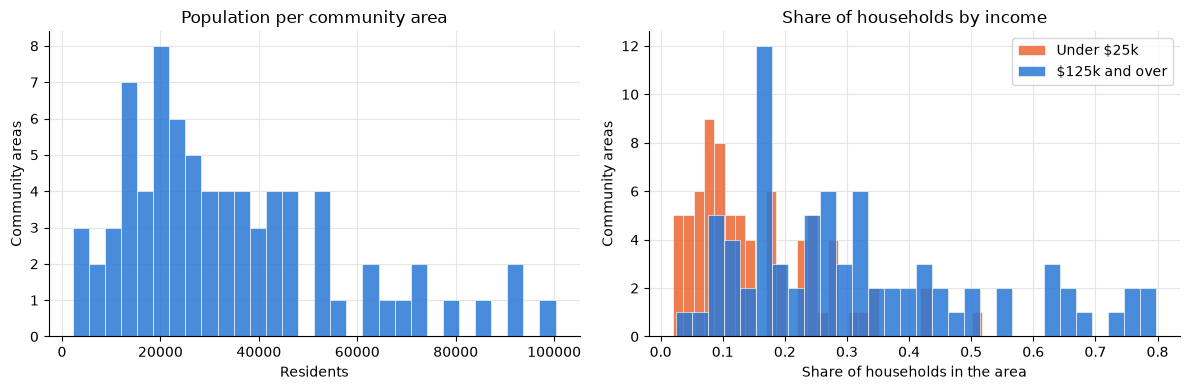

lower      upper  n_low  n_high  \
source feature                    method                                        
acs    total_population           iqr    -22,841.50  87,746.50      0       3   
                                  zscore -33,066.11 101,835.49      0       0   
       households                 iqr     -4,748.00  18,540.00      0       1   
                                  zscore  -6,086.24  20,771.51      0       1   
       share_households_under_25k iqr         -0.15       0.45      0       1   
                                  zscore      -0.16       0.47      0       1   
       share_households_125k_plus iqr         -0.23       0.84      0       0   
                                  zscore      -0.27       0.91      0       0   

                                          pct  
source feature                    method       
acs    total_population           iqr    3.90  
                                  zscore 0.00  
       households                 iqr    1.30  
                                  zscore 1.30  
       share_households_under_25k iqr    1.30  
                                  zscore 1.30  
       share_households_125k_plus iqr    0.00  
                                  zscore 0.00

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
histogram(axes[0], "acs", "total_population")
axes[0].set(title="Population per community area", xlabel="Residents", ylabel="Community areas")
histogram(axes[1], "acs", "share_households_under_25k", ORANGE, "Under $25k")
histogram(axes[1], "acs", "share_households_125k_plus", BLUE, "$125k and over")
axes[1].set(title="Share of households by income", xlabel="Share of households in the area", ylabel="Community areas")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGS / "acs.png", dpi=150, bbox_inches="tight")
plt.show()
outliers("acs")

The ACS file has one row per community area (77 rows, all from ACS year 2023), with no missing values, duplicates or non-numeric counts. Counts are written with thousands commas, so they are cleaned the same way as the CTA files. The 12 age and sex groups do not add up exactly to the total population in 50 areas, and the race groups in 37, but the gap is at most 2 people per area, which is rounding in the published estimates, so we use Total Population as given. The median area has 29,052 residents, and the IQR rule flags 3 large ones: Austin (100,278), Near North Side (91,635) and Lake View (90,652); they are real, so we keep them. The share of households earning under \$25,000 goes from 2% to 52% across areas.

## 6. NOAA daily weather, O'Hare and Midway (2018 onward)

In [19]:
checks("weather")

,check,column,count,pct,note
126,rows,,39991,100.00,
130,missing,TMAX,4405,11.02,
131,missing,TMIN,4405,11.02,
132,missing,PRCP,4750,11.88,
133,missing,SNOW,14930,37.33,
134,missing,SNWD,14273,35.69,
135,missing,AWND,13942,34.86,
136,missing,TMAX_ATTRIBUTES,4405,11.02,
137,missing,TMIN_ATTRIBUTES,4405,11.02,
138,missing,PRCP_ATTRIBUTES,4750,11.88,


In [20]:
describe("weather_ohare", "weather_midway")

count  mean   std    min    q1  median    q3  \
source         feature                                                       
weather_ohare  tmax_c          3217 16.30 11.69 -23.20  6.70   17.80 26.70   
               tmin_c          3217  6.98 10.55 -30.50 -0.50    6.70 16.70   
               prcp_mm         3217  2.65  7.35   0.00  0.00    0.00  1.30   
               snow_mm         3217  2.30 12.64   0.00  0.00    0.00  0.00   
               snow_depth_mm   3217  9.18 41.11   0.00  0.00    0.00  0.00   
               wind_ms         3217  4.24  1.53   0.90  3.10    4.10  5.20   
weather_midway tmax_c          3217 16.70 11.60 -22.70  7.20   17.80 27.20   
               tmin_c          3217  7.69 10.59 -29.90  0.00    7.20 17.20   
               prcp_mm         3213  2.53  7.32   0.00  0.00    0.00  1.00   
               snow_mm          208  0.00  0.00   0.00  0.00    0.00  0.00   
               snow_depth_mm    855 19.97 65.03   0.00  0.00    0.00  0.00   
               wind_ms         3216  4.41  1.55   0.70  3.30    4.20  5.40   

                                max  skewness  
source         feature                         
weather_ohare  tmax_c         37.80     -0.32  
               tmin_c         27.20     -0.32  
               prcp_mm        89.70      4.75  
               snow_mm       213.00      8.12  
               snow_depth_mm 530.00      6.90  
               wind_ms        12.50      0.70  
weather_midway tmax_c         38.30     -0.32  
               tmin_c         28.30     -0.31  
               prcp_mm       118.90      5.57  
               snow_mm         0.00       NaN  
               snow_depth_mm 610.00      5.03  
               wind_ms        11.60      0.72

In [21]:
outliers("weather_ohare", "weather_midway")

lower  upper  n_low  n_high   pct
source         feature       method                                    
weather_ohare  tmax_c        iqr     -23.30  56.70      0       0  0.00
                             zscore  -18.78  51.37      1       0  0.03
               tmin_c        iqr     -26.30  42.50      2       0  0.06
                             zscore  -24.67  38.63      2       0  0.06
               prcp_mm       iqr      -1.95   3.25      0     588 18.28
                             zscore  -19.39  24.70      0      74  2.30
               snow_mm       iqr       0.00   0.00      0     241  7.49
                             zscore  -35.60  40.21      0      66  2.05
               snow_depth_mm iqr       0.00   0.00      0     310  9.64
                             zscore -114.15 132.51      0      53  1.65
               wind_ms       iqr      -0.05   8.35      0      35  1.09
                             zscore   -0.35   8.83      0      22  0.68
weather_midway tmax_c        iqr     -22.80  57.20      0       0  0.00
                             zscore  -18.10  51.50      2       0  0.06
               tmin_c        iqr     -25.80  43.00      2       0  0.06
                             zscore  -24.09  39.46      2       0  0.06
               prcp_mm       iqr      -1.50   2.50      0     598 18.61
                             zscore  -19.42  24.48      0      77  2.40
               snow_mm       iqr       0.00   0.00      0       0  0.00
                             zscore    0.00   0.00      0       0  0.00
               snow_depth_mm iqr       0.00   0.00      0     171 20.00
                             zscore -175.11 215.06      0      24  2.81
               wind_ms       iqr       0.15   8.55      0      41  1.27
                             zscore   -0.25   9.06      0      24  0.75

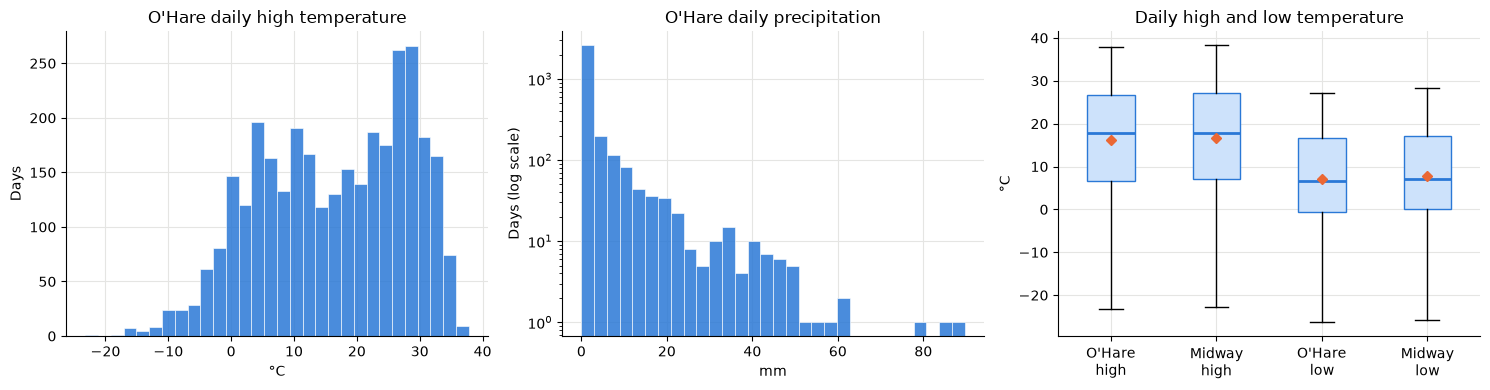

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
histogram(axes[0], "weather_ohare", "tmax_c")
axes[0].set(title="O'Hare daily high temperature", xlabel="°C", ylabel="Days")
histogram(axes[1], "weather_ohare", "prcp_mm")
axes[1].set(title="O'Hare daily precipitation", xlabel="mm", ylabel="Days (log scale)", yscale="log")
boxes(axes[2], describe("weather_ohare", "weather_midway").loc[[("weather_ohare", "tmax_c"), ("weather_midway", "tmax_c"),
                                                                ("weather_ohare", "tmin_c"), ("weather_midway", "tmin_c")]],
      ["O'Hare\nhigh", "Midway\nhigh", "O'Hare\nlow", "Midway\nlow"])
axes[2].set(title="Daily high and low temperature", ylabel="°C")
plt.tight_layout()
plt.savefig(FIGS / "weather.png", dpi=150, bbox_inches="tight")
plt.show()

Both stations have a reading for every day since 2018 (3,217 days each), with no duplicate days, no dates that fail to parse, and no day where the low is above the high. Values are stored in tenths of a unit and written with leading spaces (89% of temperature values), so the job trims them and converts them to °C, mm and m/s. Midway does not record snowfall (93.5% of days missing since 2018), so we use O'Hare for snow. Only a handful of values in the full history carry a GHCN quality flag (for example 9 daily highs), too few to matter.

The z-score rule flags the coldest days of the January 2019 polar vortex (O'Hare high of −23.2 °C and low of −30.5 °C on Jan 30, 2019) and 74 very wet days at O'Hare (over 24.7 mm, up to 89.7 mm on May 14, 2020). This is real weather, so we keep it. The IQR rule is not useful for precipitation and snow: most days are dry, so Q3 is close to 0 and it flags every rainy day (18%).

## 7. Feature scaling

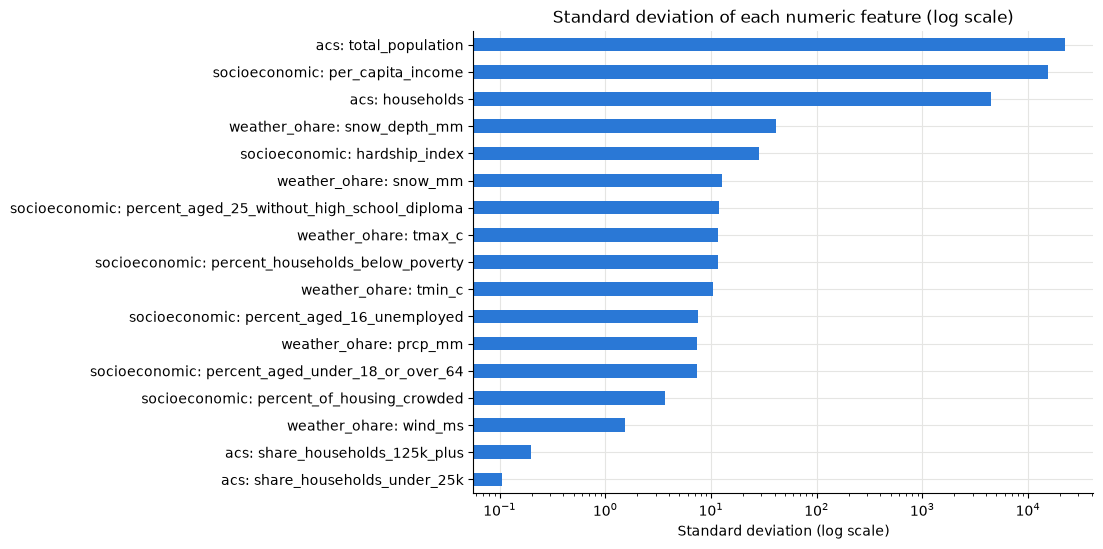

,min,max,std
name,,,
acs: share_households_under_25k,0.02,0.52,0.10
acs: share_households_125k_plus,0.03,0.80,0.20
weather_ohare: wind_ms,0.90,12.50,1.53
socioeconomic: percent_of_housing_crowded,0.30,15.80,3.68
socioeconomic: percent_aged_under_18_or_over_64,13.50,51.50,7.33
weather_ohare: prcp_mm,0.00,89.70,7.35
socioeconomic: percent_aged_16_unemployed,4.70,35.90,7.54
weather_ohare: tmin_c,-30.50,27.20,10.55
socioeconomic: percent_households_below_poverty,3.30,56.50,11.53


In [23]:
scale = (stats[stats.source.isin(["socioeconomic", "acs", "weather_ohare"])]
         .assign(name=lambda d: d.source + ": " + d.feature)
         .set_index("name")[["min", "max", "std"]].sort_values("std"))
ax = scale["std"].plot(kind="barh", logx=True, color=BLUE, figsize=(8, 6),
                       title="Standard deviation of each numeric feature (log scale)")
ax.set(xlabel="Standard deviation (log scale)", ylabel="")
plt.savefig(FIGS / "feature_scales.png", dpi=150, bbox_inches="tight")
plt.show()
scale

The features are on very different scales: the standard deviation goes from about 0.1 (income shares) and 1.5 (wind speed) up to about 15,000 (per capita income) and 22,000 (population). So we standardize numeric features (z-scores) before any distance-based method such as K-means, and use log scales for the right-skewed ones (rides, income, population). Tree-based models, such as the gradient-boosted demand model, do not need scaling.

## Summary: cleaning decisions for the supporting data

| Source | Problem found | What we did |
| --- | --- | --- |
| CTA 'L' and bus daily | Ride counts written with thousands commas (72% and 79% of rows) | Removed the commas before casting to numbers |
| CTA 'L' daily | 618 station-days listed twice, all in 2011 | Kept one copy; outside our 2018+ window |
| CTA 'L' daily | Station 40140 renamed (Skokie → Dempster-Skokie) | Join on station id, not name |
| CTA 'L' daily | 3,851 zero-ride station-days since 2018 (closed stations) | Kept; real closures, not missing data |
| 'L' stops | Location stored as text "(lat, lon)" | Parsed into numeric latitude and longitude |
| Community areas | Area stored in square feet | Converted to km² |
| Socioeconomic | City-wide total row (CHICAGO) | Removed |
| ACS | Age/sex and race groups differ from the total by up to 2 people | Kept Total Population as published |
| Weather | Values in tenths of a unit, with leading spaces | Trimmed and converted to °C, mm and m/s |
| Weather | Midway has no snowfall data | Use O'Hare for snow |
| All | High values flagged by IQR or z-score | Kept: busy stations, large or rich areas and extreme weather are real |

The cleaned tables are saved as Parquet in `gs://ride-or-rail-data-ride-or-rail-123456/results/eda_supporting/clean/`.